## Module 3: Computational Drug Discovery Project

## Project Goal:

Our goal is to help develop Cavalitide, a small-molecule GLP1 receptor agonist for weight loss that would compete with semaglutide (Ozempic and Wegovy). To do this, we ask three questions. First, how tightly does Cavalitide bind and activate the GLP1 receptor compared to semaglutide and native GLP1? We answer this by fitting a receptor binding model to Cavalitide’s binding data (Task 1). Second, what daily oral dose of Cavalitide gives a steady-state free blood concentration of about 0.5 nM? We answer this by simulating its pharmacokinetics and comparing it to Ozempic and Wegovy (Task 2). Third, what dose gives about 90% receptor activation, and is the extra dose worth it clinically? We answer this by combining the two models (Task 3). Together, these results let us judge whether Cavalitide could compete with semaglutide.

## Disease Background: 

Obesity (BMI ≥ 30) affects 40.3% of U.S. adults [1] and about 1 in 7 people worldwide [2]. It raises the risk of type 2 diabetes, heart, liver, and kidney disease, and several cancers [2]. Two gut hormones, GLP-1 and GIP, act on multiple organs to regulate appetite and metabolism. GLP-1 reduces food intake in the brain, slows gastric emptying, lowers glucagon, and raises cAMP in pancreatic beta cells to stimulate insulin release. GIP also raises insulin but promotes fat storage [3]. Modern treatments include semaglutide (sold as Ozempic and Wegovy), which mimics GLP-1 by activating its receptor, and tirzepatide, which activates both receptors [4]. Weekly semaglutide injections produced 14.9% weight loss over 68 weeks [5], and a daily pill was approved in December 2025 [6]. Yet obesity is chronic, as patients regained 2/3 of their lost weight within a year of stopping semaglutide [7], and U.S. adults who stopped GLP-1 drugs most often cited cost (36%) and side effects (33%) [8]. Patients therefore need more effective drugs that are easier to stay on. Retatrutide, which activates GLP-1, GIP, and glucagon receptors, reached 25.0% weight loss at 80 weeks in phase 3 [9], and once-monthly MariTide may improve adherence [10].

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

Brute-force Kd2 = 0.074 nM (SSE = 0.0054)
Fitted Kd2 = 0.077 nM (SSE = 0.0052)


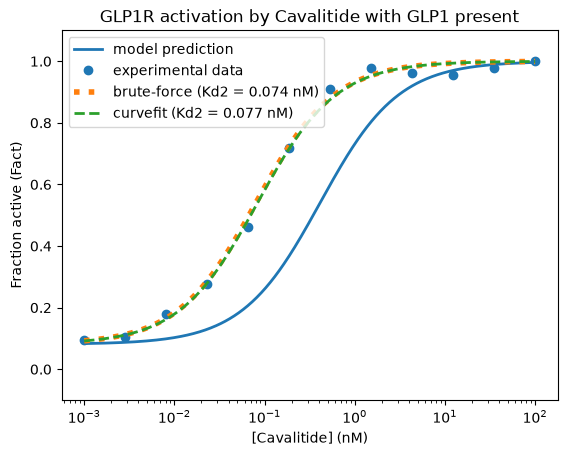

In [1]:
# fit_semaglutide_GLP1R.py
# 1a and 1b
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
Kd2 = 0.38 # default 0.38 L2, semaglutide (to fit)
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] semaglutide or cavalitide

# Load the data
# I changed the file name to load the Cavalitide data instead of the semaglutide data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

# Approach 1: Brute force optimization of Kd2: try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf
for Kd2_try in Kd2_candidates:
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_brute:
        SSE_brute = SSE
        Kd2_brute = Kd2_try
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})")

# Approach 2: Python curvefit of Kd2: related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})")


plt.figure()
line, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2), lw=2,
                     label="model prediction")
plt.semilogx(L2_loaded, Fact_loaded, "o", c=line.get_color(),
             label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=4,
             label=f"brute-force (Kd2 = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
             label=f"curvefit (Kd2 = {Kd2_fit:.3f} nM)")

plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)") # I changed this from semaglutide to Cavalitide
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present") # I changed this from semaglutide to Cavalitide
plt.legend(loc="upper left")
plt.show()

1c: The fitted Kd value of Cavalitide is 0.077 nM. The Kd of semaglutide is 0.38 nM, so Cavalitide binds GLP1R about 5 times more tightly. Cavalitide also binds more tightly than native GLP1 (Kd of 0.17 nM), in contrast to semaglutide, which binds more weakly. On the plot, this is represented by a Cavalitide curve shift to the left (blue curve uses semaglutide Kd and is clearly right-shifted relative to Cavalitide), since it needs a much lower concentration to cause the same amount of receptor activation. The advantages of this are that less drug needs to be in the blood to reach a given level of receptor activation, which could mean that less of the drug needs to be administered to achieve a similar effect. Cavalitide can also better compete against native GLP1 already occupying receptors. Some disadvantages are that even though the Kd implies tight binding, it doesn't prove effectiveness at eliciting any response from the receptor. Additionally, since the binding of the receptor is tighter, receptor activation might be harder to turn down or reverse. 

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

Ozempic: mean free concentration over last interval = 0.608 nM
Ozempic: analytical steady-state estimate = 0.612 nM


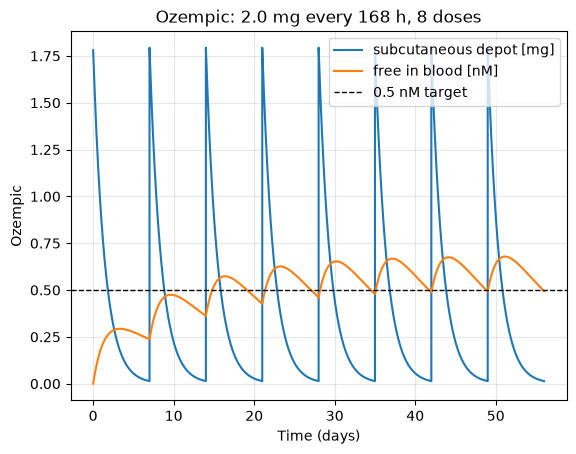

In [2]:
import numpy as np                     
import matplotlib.pyplot as plt       
from scipy.integrate import solve_ivp  # solve_ivp: numerically solves the ODEs (replaces my Euler loop)

# ===== choose product =====
drug = 'Ozempic'   # which product to simulate

# product-specific parameters
# products is a dictionary: each drug name is a key and its value is a smaller dictionary of that drug's settings
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),  # where the drug is absorbed from (only used for the plot label)
    'Wegovy':  dict(Favailable=0.01,   # low bioavailability because it is a pill
                    ka=0.0029,         # 1/h, slower absorption from the gut
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,       # 100 daily doses (100 days)
                    depot='gut (oral)'),
    # Part 2: ka from the assignment; Favailable, D, interval, n_doses ASSUMED same as Wegovy
    'Cavalitide': dict(Favailable=0.01,
                       ka=0.006,       # 1/h, the faster absorption rate given for Cavalitide
                       D=25,
                       interval=24,
                       n_doses=100,
                       depot='gut (oral)'),
    # Part 3: same drug, adjusted dose (D) to reach ~0.5 nM free at steady state
    'CavalitideOpt': dict(Favailable=0.01,
                          ka=0.006,
                          D=21,            # mg, lowered from 25 so free conc is ~0.5 nM (see the Part 3 cell below)
                          interval=24,
                          n_doses=100,
                          depot='gut (oral)'),
}
p = products[drug]   # look up the settings dictionary for the chosen drug
# pull each setting out of that dictionary into its own variable (one assignment per name, separated by commas)
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L, volume the drug is distributed in
Mw = 4113.6     # g/mol, molar mass, used to convert mg/L to nM
Ffree = 0.01    # rest of semaglutide bound to albumin (so only 1% is free)

# output grid spacing (no longer an Euler step size; solve_ivp picks its own internal steps)
dt = 0.1        # h, time between saved output points

def ODEfunc(t, y):             # right-hand side of the ODEs; solve_ivp calls this with the time t and the state y
    Asc, Cc = y                # unpack the state: depot amount and blood concentration
    dAsc = -ka*Asc             # Asc: depot amount (mg), it empties at rate ka
    dCc = ka*Asc/V - ke*Cc     # Cc: blood concentration (mg/L), gains from the depot and loses by elimination
    return [dAsc, dCc]         # return both rates of change as a list

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []      # empty lists to collect the results from each dosing interval
    y = np.array([0.0, 0.0])                 # start with no drug in the depot or in the blood
    n_steps = int(round(interval / dt))      # output points per dosing interval
    for i in range(n_doses):                 # loop over the doses, i = 0, 1, 2, ...
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot (+= adds to what is already there)
        t0 = i * interval                    # start time of this dosing interval (h)
        t_seg = t0 + dt * np.arange(n_steps + 1)   # times to save output at, from the start to the end of this interval

        # solve_ivp replaces the explicit Euler loop
        # (start, end) times, starting state y, times to save, LSODA method, tolerances for how accurate it must be
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        method='LSODA', rtol=1e-8, atol=1e-10)

        t_out.append(sol.t)                  # save the times from this interval
        Asc_out.append(sol.y[0])             # save the depot amounts (row 0 of the solution)
        Cc_out.append(sol.y[1])              # save the blood concentrations (row 1 of the solution)
        y = sol.y[:, -1].copy()              # carry state into next interval (last column = end of this interval)
    t = np.concatenate(t_out)                # join the list of pieces into one long array
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / Mw * 1e9         # mg/L -> g/L (1e-3), -> mol/L (divide by Mw), -> nmol/L (1e9)
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)   # run the simulation with this drug's settings

# --- steady-state check: mean free concentration over the last dosing interval ---
Cfree = Ffree*Cc                          # only the free fraction of the drug counts
ss = Cfree[t >= t[-1] - interval].mean()  # keep only the times in the last dosing interval, then average them
print(f"{drug}: mean free concentration over last interval = {ss:.3f} nM")   # f-string prints the value to 3 decimals

# Analytical estimate (independent of ka): mean total conc = Favailable*D/(interval*V*ke) mg/L
# (times Ffree for the free part, then converted from mg/L to nM the same way as above)
ss_est = Ffree * (Favailable*D/(interval*V*ke)) * 1e-3/Mw*1e9
print(f"{drug}: analytical steady-state estimate = {ss_est:.3f} nM")         # should be close to the simulated value

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")     # depot amount vs time, converting hours to days
plt.plot(t / 24, Cfree, label="free in blood [nM]")    # free blood concentration vs time
plt.axhline(0.5, ls='--', c='k', lw=1, label='0.5 nM target')   # dashed black horizontal line at the 0.5 nM target
plt.xlabel("Time (days)")                # x-axis label
plt.ylabel(drug)                         # y-axis label (the drug name)
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")   # title shows the dose and schedule
plt.legend()                             # show the labels from above
plt.grid(alpha=0.3)                      # light grid lines
plt.show()                               # display the figure

Wegovy: mean free concentration over last interval = 0.599 nM
Wegovy: analytical steady-state estimate = 0.601 nM


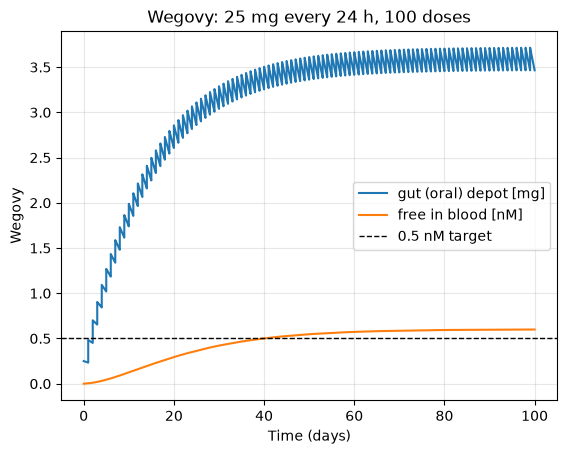

In [3]:
import numpy as np                     
import matplotlib.pyplot as plt       
from scipy.integrate import solve_ivp  # solve_ivp: numerically solves the ODEs (replaces my Euler loop)

# ===== choose product =====
drug = 'Wegovy'   # which product to simulate

# product-specific parameters
# products is a dictionary: each drug name is a key and its value is a smaller dictionary of that drug's settings
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),  # where the drug is absorbed from (only used for the plot label)
    'Wegovy':  dict(Favailable=0.01,   # low bioavailability because it is a pill
                    ka=0.0029,         # 1/h, slower absorption from the gut
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,       # 100 daily doses (100 days)
                    depot='gut (oral)'),
    # Part 2: ka from the assignment; Favailable, D, interval, n_doses ASSUMED same as Wegovy
    'Cavalitide': dict(Favailable=0.01,
                       ka=0.006,       # 1/h, the faster absorption rate given for Cavalitide
                       D=25,
                       interval=24,
                       n_doses=100,
                       depot='gut (oral)'),
    # Part 3: same drug, adjusted dose (D) to reach ~0.5 nM free at steady state
    'CavalitideOpt': dict(Favailable=0.01,
                          ka=0.006,
                          D=21,            # mg, lowered from 25 so free conc is ~0.5 nM (see the Part 3 cell below)
                          interval=24,
                          n_doses=100,
                          depot='gut (oral)'),
}
p = products[drug]   # look up the settings dictionary for the chosen drug
# pull each setting out of that dictionary into its own variable (one assignment per name, separated by commas)
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L, volume the drug is distributed in
Mw = 4113.6     # g/mol, molar mass, used to convert mg/L to nM
Ffree = 0.01    # rest of semaglutide bound to albumin (so only 1% is free)

# output grid spacing (no longer an Euler step size; solve_ivp picks its own internal steps)
dt = 0.1        # h, time between saved output points

def ODEfunc(t, y):             # right-hand side of the ODEs; solve_ivp calls this with the time t and the state y
    Asc, Cc = y                # unpack the state: depot amount and blood concentration
    dAsc = -ka*Asc             # Asc: depot amount (mg), it empties at rate ka
    dCc = ka*Asc/V - ke*Cc     # Cc: blood concentration (mg/L), gains from the depot and loses by elimination
    return [dAsc, dCc]         # return both rates of change as a list

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []      # empty lists to collect the results from each dosing interval
    y = np.array([0.0, 0.0])                 # start with no drug in the depot or in the blood
    n_steps = int(round(interval / dt))      # output points per dosing interval
    for i in range(n_doses):                 # loop over the doses, i = 0, 1, 2, ...
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot (+= adds to what is already there)
        t0 = i * interval                    # start time of this dosing interval (h)
        t_seg = t0 + dt * np.arange(n_steps + 1)   # times to save output at, from the start to the end of this interval

        # solve_ivp replaces the explicit Euler loop
        # (start, end) times, starting state y, times to save, LSODA method, tolerances for how accurate it must be
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        method='LSODA', rtol=1e-8, atol=1e-10)

        t_out.append(sol.t)                  # save the times from this interval
        Asc_out.append(sol.y[0])             # save the depot amounts (row 0 of the solution)
        Cc_out.append(sol.y[1])              # save the blood concentrations (row 1 of the solution)
        y = sol.y[:, -1].copy()              # carry state into next interval (last column = end of this interval)
    t = np.concatenate(t_out)                # join the list of pieces into one long array
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / Mw * 1e9         # mg/L -> g/L (1e-3), -> mol/L (divide by Mw), -> nmol/L (1e9)
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)   # run the simulation with this drug's settings

# --- steady-state check: mean free concentration over the last dosing interval ---
Cfree = Ffree*Cc                          # only the free fraction of the drug counts
ss = Cfree[t >= t[-1] - interval].mean()  # keep only the times in the last dosing interval, then average them
print(f"{drug}: mean free concentration over last interval = {ss:.3f} nM")   # f-string prints the value to 3 decimals

# Analytical estimate (independent of ka): mean total conc = Favailable*D/(interval*V*ke) mg/L
# (times Ffree for the free part, then converted from mg/L to nM the same way as above)
ss_est = Ffree * (Favailable*D/(interval*V*ke)) * 1e-3/Mw*1e9
print(f"{drug}: analytical steady-state estimate = {ss_est:.3f} nM")         # should be close to the simulated value

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")     # depot amount vs time, converting hours to days
plt.plot(t / 24, Cfree, label="free in blood [nM]")    # free blood concentration vs time
plt.axhline(0.5, ls='--', c='k', lw=1, label='0.5 nM target')   # dashed black horizontal line at the 0.5 nM target
plt.xlabel("Time (days)")                # x-axis label
plt.ylabel(drug)                         # y-axis label (the drug name)
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")   # title shows the dose and schedule
plt.legend()                             # show the labels from above
plt.grid(alpha=0.3)                      # light grid lines
plt.show()                               # display the figure

Cavalitide: mean free concentration over last interval = 0.601 nM
Cavalitide: analytical steady-state estimate = 0.601 nM


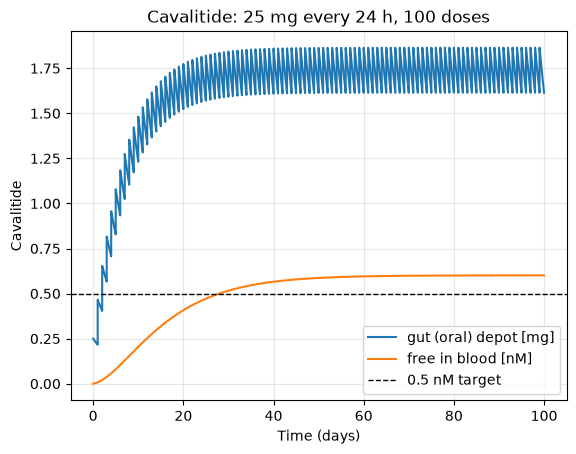

In [4]:
import numpy as np                     
import matplotlib.pyplot as plt       
from scipy.integrate import solve_ivp  # solve_ivp: numerically solves the ODEs (replaces my Euler loop)

# ===== choose product =====
drug = 'Cavalitide'   # which product to simulate

# product-specific parameters
# products is a dictionary: each drug name is a key and its value is a smaller dictionary of that drug's settings
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),  # where the drug is absorbed from (only used for the plot label)
    'Wegovy':  dict(Favailable=0.01,   # low bioavailability because it is a pill
                    ka=0.0029,         # 1/h, slower absorption from the gut
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,       # 100 daily doses (100 days)
                    depot='gut (oral)'),
    # Part 2: ka from the assignment; Favailable, D, interval, n_doses ASSUMED same as Wegovy
    'Cavalitide': dict(Favailable=0.01,
                       ka=0.006,       # 1/h, the faster absorption rate given for Cavalitide
                       D=25,
                       interval=24,
                       n_doses=100,
                       depot='gut (oral)'),
    # Part 3: same drug, adjusted dose (D) to reach ~0.5 nM free at steady state
    'CavalitideOpt': dict(Favailable=0.01,
                          ka=0.006,
                          D=21,            # mg, lowered from 25 so free conc is ~0.5 nM (see the Part 3 cell below)
                          interval=24,
                          n_doses=100,
                          depot='gut (oral)'),
}
p = products[drug]   # look up the settings dictionary for the chosen drug
# pull each setting out of that dictionary into its own variable (one assignment per name, separated by commas)
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L, volume the drug is distributed in
Mw = 4113.6     # g/mol, molar mass, used to convert mg/L to nM
Ffree = 0.01    # rest of semaglutide bound to albumin (so only 1% is free)

# output grid spacing (no longer an Euler step size; solve_ivp picks its own internal steps)
dt = 0.1        # h, time between saved output points

def ODEfunc(t, y):             # right-hand side of the ODEs; solve_ivp calls this with the time t and the state y
    Asc, Cc = y                # unpack the state: depot amount and blood concentration
    dAsc = -ka*Asc             # Asc: depot amount (mg), it empties at rate ka
    dCc = ka*Asc/V - ke*Cc     # Cc: blood concentration (mg/L), gains from the depot and loses by elimination
    return [dAsc, dCc]         # return both rates of change as a list

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []      # empty lists to collect the results from each dosing interval
    y = np.array([0.0, 0.0])                 # start with no drug in the depot or in the blood
    n_steps = int(round(interval / dt))      # output points per dosing interval
    for i in range(n_doses):                 # loop over the doses, i = 0, 1, 2, ...
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot (+= adds to what is already there)
        t0 = i * interval                    # start time of this dosing interval (h)
        t_seg = t0 + dt * np.arange(n_steps + 1)   # times to save output at, from the start to the end of this interval

        # solve_ivp replaces the explicit Euler loop
        # (start, end) times, starting state y, times to save, LSODA method, tolerances for how accurate it must be
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        method='LSODA', rtol=1e-8, atol=1e-10)

        t_out.append(sol.t)                  # save the times from this interval
        Asc_out.append(sol.y[0])             # save the depot amounts (row 0 of the solution)
        Cc_out.append(sol.y[1])              # save the blood concentrations (row 1 of the solution)
        y = sol.y[:, -1].copy()              # carry state into next interval (last column = end of this interval)
    t = np.concatenate(t_out)                # join the list of pieces into one long array
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / Mw * 1e9         # mg/L -> g/L (1e-3), -> mol/L (divide by Mw), -> nmol/L (1e9)
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)   # run the simulation with this drug's settings

# --- steady-state check: mean free concentration over the last dosing interval ---
Cfree = Ffree*Cc                          # only the free fraction of the drug counts
ss = Cfree[t >= t[-1] - interval].mean()  # keep only the times in the last dosing interval, then average them
print(f"{drug}: mean free concentration over last interval = {ss:.3f} nM")   # f-string prints the value to 3 decimals

# Analytical estimate (independent of ka): mean total conc = Favailable*D/(interval*V*ke) mg/L
# (times Ffree for the free part, then converted from mg/L to nM the same way as above)
ss_est = Ffree * (Favailable*D/(interval*V*ke)) * 1e-3/Mw*1e9
print(f"{drug}: analytical steady-state estimate = {ss_est:.3f} nM")         # should be close to the simulated value

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")     # depot amount vs time, converting hours to days
plt.plot(t / 24, Cfree, label="free in blood [nM]")    # free blood concentration vs time
plt.axhline(0.5, ls='--', c='k', lw=1, label='0.5 nM target')   # dashed black horizontal line at the 0.5 nM target
plt.xlabel("Time (days)")                # x-axis label
plt.ylabel(drug)                         # y-axis label (the drug name)
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")   # title shows the dose and schedule
plt.legend()                             # show the labels from above
plt.grid(alpha=0.3)                      # light grid lines
plt.show()                               # display the figure

CavalitideOpt: mean free concentration over last interval = 0.500 nM
CavalitideOpt: analytical steady-state estimate = 0.500 nM


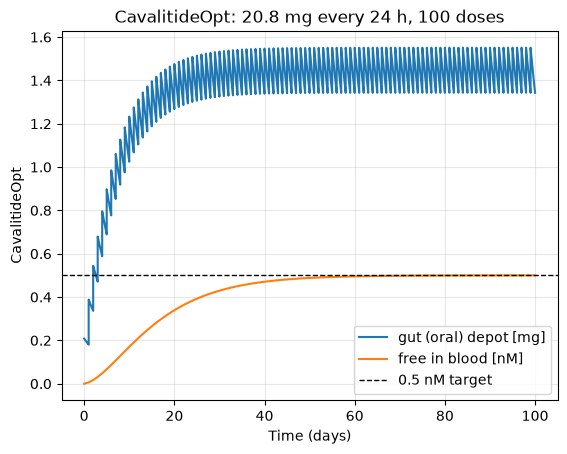

In [5]:
import numpy as np                     
import matplotlib.pyplot as plt        
from scipy.integrate import solve_ivp  # solve_ivp: numerically solves the ODEs (replaces my Euler loop)

# ===== choose product =====
drug = 'CavalitideOpt'   # which product to simulate (change this name to switch between the products below)

# product-specific parameters
# products is a dictionary: each drug name is a key and its value is a smaller dictionary of that drug's settings
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),  # where the drug is absorbed from (only used for the plot label)
    'Wegovy':  dict(Favailable=0.01,   # low bioavailability because it is a pill
                    ka=0.0029,         # 1/h, slower absorption from the gut
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,       # 100 daily doses (100 days)
                    depot='gut (oral)'),
    # Part 2: ka from the assignment; Favailable, D, interval, n_doses ASSUMED same as Wegovy
    'Cavalitide': dict(Favailable=0.01,
                       ka=0.006,       # 1/h, the faster absorption rate given for Cavalitide
                       D=25,
                       interval=24,
                       n_doses=100,
                       depot='gut (oral)'),
    # Part 3: same drug, adjusted dose (D) to reach ~0.5 nM free at steady state
    'CavalitideOpt': dict(Favailable=0.01,
                          ka=0.006,
                          D=20.8,          # mg, lowered from 25 so free conc is ~0.5 nM (25*0.5/0.601 = 20.8)
                          interval=24,
                          n_doses=100,
                          depot='gut (oral)'),
}
p = products[drug]   # look up the settings dictionary for the chosen drug
# pull each setting out of that dictionary into its own variable (one assignment per name, separated by commas)
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L, volume the drug is distributed in
Mw = 4113.6     # g/mol, molar mass, used to convert mg/L to nM
Ffree = 0.01    # rest of semaglutide bound to albumin (so only 1% is free)

# output grid spacing (no longer an Euler step size; solve_ivp picks its own internal steps)
dt = 0.1        # h, time between saved output points

def ODEfunc(t, y):             # right-hand side of the ODEs; solve_ivp calls this with the time t and the state y
    Asc, Cc = y                # unpack the state: depot amount and blood concentration
    dAsc = -ka*Asc             # Asc: depot amount (mg), it empties at rate ka
    dCc = ka*Asc/V - ke*Cc     # Cc: blood concentration (mg/L), gains from the depot and loses by elimination
    return [dAsc, dCc]         # return both rates of change as a list

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []      # empty lists to collect the results from each dosing interval
    y = np.array([0.0, 0.0])                 # start with no drug in the depot or in the blood
    n_steps = int(round(interval / dt))      # output points per dosing interval
    for i in range(n_doses):                 # loop over the doses, i = 0, 1, 2, ...
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot (+= adds to what is already there)
        t0 = i * interval                    # start time of this dosing interval (h)
        t_seg = t0 + dt * np.arange(n_steps + 1)   # times to save output at, from the start to the end of this interval

        # solve_ivp replaces the explicit Euler loop
        # (start, end) times, starting state y, times to save, LSODA method, tolerances for how accurate it must be
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        method='LSODA', rtol=1e-8, atol=1e-10)

        t_out.append(sol.t)                  # save the times from this interval
        Asc_out.append(sol.y[0])             # save the depot amounts (row 0 of the solution)
        Cc_out.append(sol.y[1])              # save the blood concentrations (row 1 of the solution)
        y = sol.y[:, -1].copy()              # carry state into next interval (last column = end of this interval)
    t = np.concatenate(t_out)                # join the list of pieces into one long array
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / Mw * 1e9         # mg/L -> g/L (1e-3), -> mol/L (divide by Mw), -> nmol/L (1e9)
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)   # run the simulation with this drug's settings

# --- steady-state check: mean free concentration over the last dosing interval ---
Cfree = Ffree*Cc                          # only the free fraction of the drug counts
ss = Cfree[t >= t[-1] - interval].mean()  # keep only the times in the last dosing interval, then average them
print(f"{drug}: mean free concentration over last interval = {ss:.3f} nM")   # f-string prints the value to 3 decimals

# Analytical estimate (independent of ka): mean total conc = Favailable*D/(interval*V*ke) mg/L
# (times Ffree for the free part, then converted from mg/L to nM the same way as above)
ss_est = Ffree * (Favailable*D/(interval*V*ke)) * 1e-3/Mw*1e9
print(f"{drug}: analytical steady-state estimate = {ss_est:.3f} nM")         # should be close to the simulated value

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")     # depot amount vs time, converting hours to days
plt.plot(t / 24, Cfree, label="free in blood [nM]")    # free blood concentration vs time
plt.axhline(0.5, ls='--', c='k', lw=1, label='0.5 nM target')   # dashed black horizontal line at the 0.5 nM target
plt.xlabel("Time (days)")                # x-axis label
plt.ylabel(drug)                         # y-axis label (the drug name)
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")   # title shows the dose and schedule
plt.legend()                             # show the labels from above
plt.grid(alpha=0.3)                      # light grid lines
plt.show()                               # display the figure

For this part, we changed only the dose per pill by lowering it from 25 mg to 20.8 mg. The dosing interval (24 hours), Favailable, and ka were unchanged. Cavalitide’s faster absorption (ka = 0.006) did not change the steady-state average, because it depends on the dose, bioavailability, volume, and elimination, not on ka. At 25 mg, the steady-state free concentration was 0.601 nM, above the 0.5 nM target. Steady-state concentration scales linearly with dose, so we scaled the dose by 0.5/0.601 (25 × 0.5/0.601 = 20.8 mg, a 17% reduction). The simulation gives a steady-state free concentration of 0.500 nM, which matches the analytical estimate of 0.500 nM. The faster absorption does not change the steady-state level, but it does make Cavalitide reach steady state sooner than Wegovy, as shown in our Conclusions.

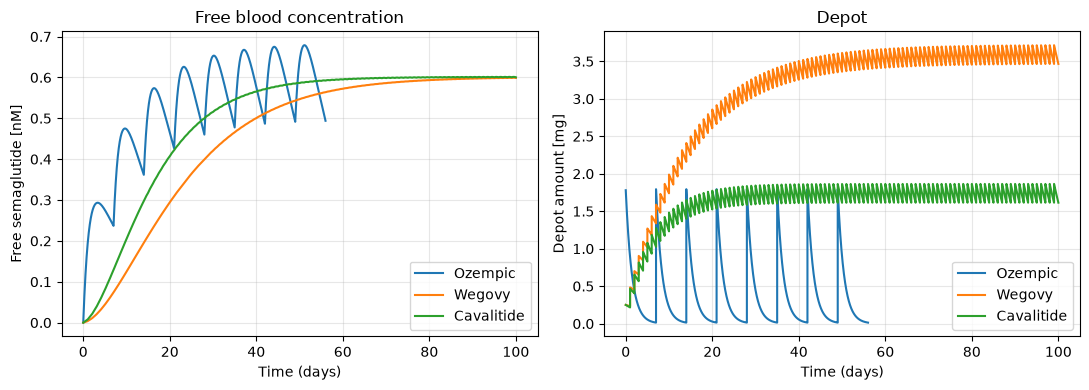

In [6]:
results = {}      # empty dictionary to store the results for each drug
for drug in ['Ozempic', 'Wegovy', 'Cavalitide']:     # loop over the three drugs
    products = {                                     # same settings as in the cells above
        'Ozempic': dict(Favailable=0.89, ka=0.029, D=2.0, interval=168, n_doses=8, depot='subcutaneous'),
        'Wegovy': dict(Favailable=0.01, ka=0.0029, D=25, interval=24, n_doses=100, depot='gut (oral)'),
        'Cavalitide': dict(Favailable=0.01, ka=0.006, D=25, interval=24, n_doses=100, depot='gut (oral)')
    }
    p = products[drug]                               # settings for the current drug
    Favailable, ka, D = p['Favailable'], p['ka'], p['D']                 # unpack the settings into variables
    interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']   # (simulate and ODEfunc read these global variables)
    t, Asc, Cc = simulate(D, n_doses, interval, dt)  # run the simulation for this drug
    results[drug] = (t, Asc, Ffree*Cc)               # store time, depot, and free concentration under the drug's name

fig, ax = plt.subplots(1, 2, figsize=(11, 4))        # one figure with two plots side by side
for drug, (t, Asc, Cfree) in results.items():        # loop through each stored result (key, value pair)
    ax[0].plot(t/24, Cfree, label=drug)              # left plot: free blood concentration, hours converted to days
    ax[1].plot(t/24, Asc, label=drug)                # right plot: depot amount
ax[0].set(xlabel="Time (days)", ylabel="Free semaglutide [nM]", title="Free blood concentration")   # labels for the left plot
ax[1].set(xlabel="Time (days)", ylabel="Depot amount [mg]", title="Depot")                           # labels for the right plot
for a in ax:                                         # add a legend and grid to both plots
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout()                                   # stop the two plots from overlapping
plt.show()                                           # display the figure

## Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.

Phase 1: D = 20.80 mg | free = 0.500 nM | Fact = 0.868
Free Cavalitide needed for 90% active: 0.686 nM -> D_opt = 28.54 mg
Phase 2 (optimized): D = 28.54 mg | free = 0.686 nM | Fact = 0.900


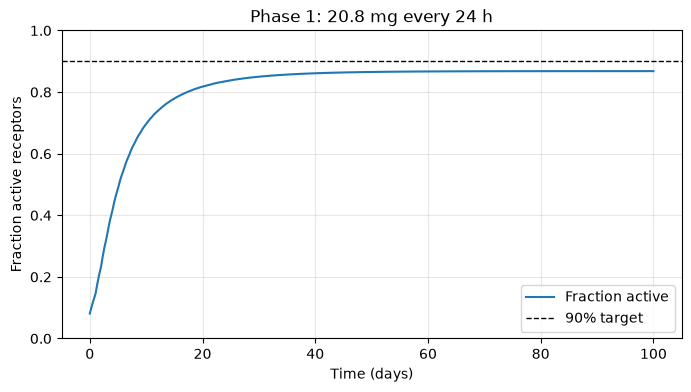

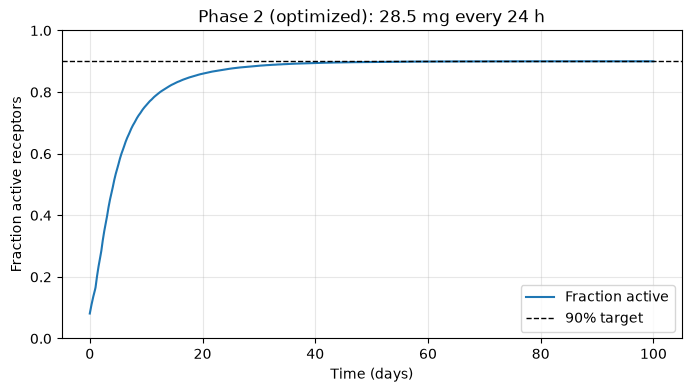

In [7]:
# cavalitidePKPD.py
import numpy as np                       
import matplotlib.pyplot as plt          
from scipy.integrate import solve_ivp    # solve_ivp: numerically solves the PK differential equations

# ---------- PD parameters ----------
Kd1 = 0.17     # nM, GLP1
Kd2 = 0.077    # nM, Cavalitide (fitted in Task 1; was 0.38 = semaglutide)
L1 = 0.015     # nM, GLP1 (fasting)

# ---------- PK parameters ----------
Favailable = 0.01   # bioavailability of the pill, assumed same as Wegovy
ka = 0.006          # 1/h, Cavalitide absorption rate from the assignment
interval = 24       # h, one pill per day
n_doses = 100       # 100 daily doses so the model covers the first 100 days
dt = 0.1            # h, spacing of the saved output points
ke = 0.0039         # 1/h, elimination rate (same as semaglutide)
V = 10.8            # L, volume of distribution (same as semaglutide)
Mw = 4113.6         # g/mol, molar mass, used to convert mg/L to nM
Ffree = 0.01        # fraction of the drug that is free (not bound to albumin)

def Fact(L1, L2, Kd1, Kd2):    # PD model from Task 1: takes both ligand concentrations and both Kd values
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)    # equilibrium binding equation with two competing ligands

def ODEfunc(t, y):             # right-hand side of the PK ODEs; solve_ivp calls this with time t and state y
    Asc, Cc = y                # unpack the state: depot amount and blood concentration
    dAsc = -ka*Asc             # depot empties at rate ka
    dCc = ka*Asc/V - ke*Cc     # blood gains drug from the depot and loses it by elimination
    return [dAsc, dCc]         # return both rates of change

def simulate(D, n_doses, interval, dt):
    """Return time (h), depot amount (mg), and total blood concentration (nM)."""
    t_out, Asc_out, Cc_out = [], [], []     # empty lists to collect each day's results
    y = np.array([0.0, 0.0])                # start with no drug in the depot or blood
    n_steps = int(round(interval / dt))     # number of output points in one dosing interval
    for i in range(n_doses):                # loop over the doses, i = 0, 1, 2, ...
        y[0] += Favailable * D              # the absorbed part of each pill enters the depot (+= adds to what is there)
        t0 = i * interval                   # start time of this interval (h)
        t_seg = t0 + dt * np.arange(n_steps + 1)    # times to save output at, from the start to the end of this interval
        # solve this one day with solve_ivp, starting from where the last day ended
        # arguments: the ODE function, (start, end) time, starting state, times to save, method, accuracy tolerances
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        method="LSODA", rtol=1e-8, atol=1e-10)
        if not sol.success:                 # sol.success is False if the solver failed
            raise RuntimeError(sol.message) # stop and show the solver's error message
        t_out.append(sol.t); Asc_out.append(sol.y[0]); Cc_out.append(sol.y[1])   # save times, depot (row 0), and blood conc (row 1)
        y = sol.y[:, -1].copy()             # carry the ending state (last column) into the next day
    t = np.concatenate(t_out)               # join the list of pieces into one long array
    Asc = np.concatenate(Asc_out)
    Cc_nM = np.concatenate(Cc_out) * 1e-3 / Mw * 1e9    # mg/L -> g/L (1e-3), -> mol/L (divide by Mw), -> nmol/L (1e9)
    return t, Asc, Cc_nM

def run_and_plot(D, title):
    """Simulate one dose, embed PD model, print steady state, make one figure."""
    t, Asc, Cc = simulate(D, n_doses, interval, dt)    # run the PK simulation for dose D
    Cfree = Ffree * Cc                    # free Cavalitide [nM] = L2
    Fa = Fact(L1, Cfree, Kd1, Kd2)        # PK output feeds the PD model
    last = t >= t[-1] - interval          # True for times in the last dosing interval (steady state)
    print(f"{title}: D = {D:.2f} mg | free = {Cfree[last].mean():.3f} nM | "
          f"Fact = {Fa[last].mean():.3f}")   # print the steady-state averages (mean over the last interval)

    fig, ax = plt.subplots(figsize=(8, 4))  # make a figure with one set of axes
    ax.plot(t / 24, Fa, label="Fraction active")    # fraction of active receptors vs time in days
    ax.axhline(0.9, ls="--", c="k", lw=1, label="90% target")   # dashed black line at the 90% target
    ax.set(xlabel="Time (days)", ylabel="Fraction active receptors",
           title=f"{title}: {D:.1f} mg every {interval} h", ylim=(0, 1))   # labels, title, and y-axis from 0 to 1
    ax.legend(); ax.grid(alpha=0.3)         # show the labels, add light grid lines
    return Cfree[last].mean()               # steady-state free concentration, used for the dose scaling below

# ---------- Image 1: Phase 1 dose (0.5 nM) ----------
D_reference = 20.8                          # mg, the dose from Task 2 part 3 that gives 0.5 nM free
ref_mean = run_and_plot(D_reference, "Phase 1")   # run it and keep the steady-state free concentration

# ---------- dose needed for 90% active ----------
f_target = 0.90                             # target fraction of active receptors
# I solved the Fact equation for L2 (free Cavalitide) to find the concentration that gives 90% active
L2_needed = (f_target*Kd2*(Kd1 + L1) - Kd2*L1) / (Kd1*(1 - f_target))  # nM free
D_opt = D_reference * L2_needed / ref_mean      # steady-state conc scales linearly with dose
print(f"Free Cavalitide needed for 90% active: {L2_needed:.3f} nM -> D_opt = {D_opt:.2f} mg")

# ---------- Image 2: optimized Phase 2 dose ----------
run_and_plot(D_opt, "Phase 2 (optimized)")  # run the optimized dose and make the second figure

plt.show()                                  # display both figures

Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.

- For this task, we adjusted the dose per pill from about 20.8 mg to about 28.5 mg a day. The dosing interval was kept at 24 hours, and Favailable and ka were unchanged. Steady-state drug concentration scales linearly with the dose, while receptor activation saturates. Because of this, we solved the binding equation for the free Cavalitide concentration that gives 90% activation (about 0.69 nM). Then, using that, we scaled the dose to reach it.
- From this, we can interpret that a 37% higher dose raises receptor activation by about 3 percentage points (from 86.8% to 90%). This cuts the inactive receptors from about 13% to 10%. Clinically, the higher dose could mean stronger appetite suppression and more weight loss. Phase 2 is the correct setting to test this, because it focuses on efficacy. However, the gain is small relative to the dose increase, so the benefit must be weighed against side effects such as nausea and the higher cost of a larger pill.

## Conclusions:

Our analysis shows that the main advantage of Cavalitide over semaglutide is how tightly it binds the receptor, not how it moves through the body. Its fitted Kd (0.077 nM) is tighter than semaglutide’s (0.38 nM). At the roughly 0.5–0.6 nM free concentration that semaglutide reaches in the simulations, Cavalitide activates around 87–89% of GLP1 receptors, compared with only around 58–63% for semaglutide. This means that semaglutide would need around 2.5 nM free drug to match Cavalitide’s 87%.

In Task 2, Cavalitide had a faster absorption (ka = 0.006 vs. 0.0029 1/h), reached steady state sooner (about 34 vs. 48 days to 90% of steady state at 25 mg), and had a smaller gut depot. It did not change the steady-state average, which depends on the dose, volume, bioavailability, and elimination. A 20.8 mg daily dose gave 0.5 nM and 87% of receptors active, and 28.5 mg gave 90%. For 37% more drug, only 3% more of the receptors become active (87% to 90%), because most receptors are already active at this dose. One anomaly is that Cavalitide’s binding data is not perfectly smooth: the fraction active falls slightly from 0.979 at 1.5 nM to 0.961 at 4.3 nM, even though more drug should not lower activation, which suggests measurement noise. A second surprising result is that Cavalitide’s faster absorption did not raise the steady-state concentration at all, only how quickly it was reached.

Compared with injected semaglutide (Ozempic), Cavalitide offers needle-free dosing and more consistent daily levels. Compared with oral Wegovy, it could reach the same receptor activation with a lower dose. However, receptor activation is not weight loss. Gastrointestinal side effects were the most common adverse events in recent oral GLP-1 obesity trials [17, 18], and binding the receptor more tightly could make them worse at higher doses. Cavalitide would also be entering a market that already has two oral GLP-1 pills [15, 16]. While it is promising, it needs data on its bioavailability, efficacy, and tolerability.

We recommend potentially moving Cavalitide into a Phase 1 trial to measure how it actually behaves in the body. We would start near 20.8 mg and test 28.5 mg in Phase 2 only if side effects are tolerable. There are also ethical concerns. Our doses assume Cavalitide behaves like semaglutide in the body, which is probably wrong for a molecule much smaller than semaglutide, so our results should not be used to dose people without real data. A 37% larger dose for only 3% more active receptors would expose patients to more risk of side effects without a proven benefit. Cost also matters, since 36% of U.S. adults who stopped GLP-1 drugs cited it [8], so a new pill only helps if patients can afford to stay on it.


## Limitations and Future Work:


Validation: Since Cavalitide is fictional and has no data, the semaglutide portion of the model is the only component that can be validated. Our Task 2 simulations of Ozempic and Wegovy showed steady-state free drug concentrations of 0.608 nM and 0.599 nM. Values in other published studies we found were for total drug, of which 1% is free in our model, so our totals are 0.608/0.01 = 60.8 nM for Ozempic and 0.599/0.01 = 59.9 nM for Wegovy. For Ozempic, the FDA, in a document including prescribing information for 2 mg weekly semaglutide (the same as ours), reports a mean steady-state concentration of 222.1 ng/mL, which when divided by semaglutide’s molar mass of 4113.6 g/mol, gives a concentration of 54.0 nM, so our reported concentration of 60.8 nM is about 13% higher, since (60.8 − 54.0)/54.0 = 0.13 [11]. For the Wegovy pill, the FDA prescribing information reports an average steady-state concentration of 77 nM for the 25 mg tablet (the same as ours), so our reported value of 59.9 nM is about 22% lower, since (77 − 59.9)/77 = 0.22 [12]. Within our own code, the simulated and analytical steady states also agree (0.608 vs 0.612 nM for Ozempic, and 0.599 vs 0.601 nM for Wegovy), which confirms that our implementation for the solve_ivp portion was correct.

Limitations: Since only the absorption rate was given for Cavalitide, its bioavailability, elimination rate, volume of distribution, free fraction, and molecular weight are all the same as for semaglutide. Since Cavalitide was described as a small molecule, this is probably wrong. The conversion to nM divides by molecular weight, so the concentrations that we showed in our analysis would likely be significantly higher, and this is significant because our Phase 1 and 2 doses depend on those assumptions. Our models are also simplified versions compared to literature, as our PK model is a single compartment while typical population PK studies use two compartments [13, 14]. We also only predict one value for an average patient and do not account for variability between patients. In the PD model, receptor activation assumes that there is equilibrium binding with fasting GLP1 fixed at 0.015 nM, and it ignores biological phenomena like receptor desensitization or downstream signaling effects. The 90% receptor activation that we found also does not correlate to any clinical findings, as we did not model clinical effects of the drug on patients such as weight loss or side effects. Another limitation is that the Cavalitide Kd we estimated comes from 12 measurements that vary quite significantly and were each measured only once, so there is no error range accounting for possible variance in the Kd value. Because the dose we calculated is directly proportional to the Kd, any error in the Kd propagates to the dose recommendation.

With more time and data, we would include multiple measurements of Cavalitide concentration to put an error bar on Kd, and run functional assays such as cAMP to measure activation inside the cell and downstream signaling effects instead of just binding. We would also aim to obtain real Cavalitide PK data instead of copying values from semaglutide, potentially through running a Phase 1 trial on humans. To better simulate the real-world, we could also model GLP1 changing throughout the day, especially around meals, instead of holding it constant. Finally, we would use clinical trial data on weight loss and side effects at different doses to find what level of receptor activation works clinically, since our 90% target is not tied to clinical outcomes.



## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*

- We used Claude (Anthropic) to help fix errors and write the solve_ivp PK code, fit the Cavalitide Kd, and calculate the doses for Tasks 2 and 3. We verified that assumption and checked the results against the analytical steady-state formula.
- Claude was used to suggest changes to the disease background section to get it down to 200 words.
- Claude was used to find published studies to reference in the limitations section that included real pharmokinetic data, as it was difficult to find studies with the necessary data by manually searching.
- Claude was used to turn website and paper links into a formatted bibliography with correctly numbered in-text citations 
- Claude was used within the receptor binding, pharmacokinetic modeling, and dose optimization sections to explain how to use various np., scipy., and other functions, including numerical ODE solving, nonlinear curve fitting, and optimization methods, and to explain how to turn results into graphs that were legible and optimized for showing the respective data. Claude and VSCode Auto-Generate Feature were used to autogenerate some of the more technical parts of the code related to creating figures in these sections.
- Claude was used to help understand and find sources to use for our conclusion.
- AI was used to check grammar and vocabulary for written sections. 
- Used Claude to check that we included everything from the rubric
- All code, analyses, statistical tests, interpretations, and conclusions were independently reviewed and verified by us before inclusion. AI-generated suggestions were treated as drafts and were modified when necessary to ensure accuracy and consistency with the dataset. AI was not used to generate results, fabricate data, or draw conclusions without verification from the underlying analyses.

## GitHub Repository Link:
*https://github.com/KartikeyaV/BME-2315-Module-3*


## References:

1. NCHS, CDC. Obesity and Overweight Prevalence in Adults, August 2021–August 2023. https://www.cdc.gov/nchs/data/hestat/hestat111.htm
2. World Health Organization. Obesity and overweight fact sheet. https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight
3. Lecture 1, slides 12–13 (J Diabetes Investig 2010;1(1-2):8–23); Tschöp et al., Diabetologia 2023. https://pubmed.ncbi.nlm.nih.gov/37209227/
4. Lecture 1, slide 17; Brandt et al., Peptides 2018. https://www.sciencedirect.com/science/article/pii/S0196978117303960
5. Wilding et al., N Engl J Med 2021;384:989–1002 (STEP 1). https://pubmed.ncbi.nlm.nih.gov/33567185/
6. Applied Clinical Trials. FDA Approves Oral Wegovy (Dec 2025). https://appliedclinicaltrialsonline.com/view/fda-approves-oral-wegovy-positive-oasis-trial-results
7. Wilding et al., Weight regain and cardiometabolic effects after withdrawal of semaglutide: the STEP 1 trial extension. Diabetes Obes Metab 2022. https://pmc.ncbi.nlm.nih.gov/articles/PMC9542252/ (PubMed backup: https://pubmed.ncbi.nlm.nih.gov/35441470/)
8. Discontinuation of glucagon-like peptide-1 receptor agonists among US adults: A national survey. J Manag Care Spec Pharm 2026;32(8):903. https://doi.org/10.18553/jmcp.2026.32.8.903
9. Jastreboff et al., Retatrutide, a triple hormone receptor agonist, for treatment of obesity (TRIUMPH-1). N Engl J Med 2026. https://doi.org/10.1056/NEJMoa2604169
10. AJMC. Weight-Loss Drug Maridebart Cafraglutide Shows Efficacy in Phase 2 Trial (1 Jul 2025). https://www.ajmc.com/view/weight-loss-drug-maridebart-cafraglutide-shows-efficacy-in-phase-2-trial
11. Novo Nordisk. Ozempic (semaglutide) injection, prescribing information (revised 05/2026), section 12.3. U.S. Food and Drug Administration. https://www.accessdata.fda.gov/drugsatfda_docs/label/2026/209637s038lbl.pdf
12. Novo Nordisk. Wegovy (semaglutide) tablets, prescribing information, section 12.3. U.S. Food and Drug Administration. https://www.accessdata.fda.gov/drugsatfda_docs/label/2026/218316s007lbl.pdf
13. Overgaard RV, Delff PH, Petri KCC, Anderson TW, Flint A, Ingwersen SH. Population pharmacokinetics of semaglutide for type 2 diabetes. Diabetes Therapy. 2019;10(2):649–662. https://doi.org/10.1007/s13300-019-0581-y
14. Overgaard RV, Navarria A, Ingwersen SH, Bækdal TA, Kildemoes RJ. Clinical pharmacokinetics of oral semaglutide: analyses of data from clinical pharmacology trials. Clinical Pharmacokinetics. 2021;60(10):1335–1348. https://doi.org/10.1007/s40262-021-01025-x
15. Aleccia, J. (2026, April 1). FDA grants speedy approval to Eli Lilly’s weight-loss pill for obesity. Associated Press. https://abc7news.com/post/fda-grants-speedy-approval-eli-lillys-weight-loss-glp-1-pill-foundayo-obesity/18823509/
16. FDA approves first oral GLP-1 for weight management. (2025, December 23). Pharmacy Times. https://www.pharmacytimes.com/view/fda-approves-first-oral-glp-1-for-weight-management
17. Wharton, S., Aronne, L. J., Stefanski, A., Alfaris, N. F., Ciudin, A., Yokote, K., Halpern, B., Shukla, A. P., Zhou, C., Macpherson, L., Allen, S. E., Ahmad, N. N., & Klise, S. R. (2025). Orforglipron, an oral small-molecule GLP-1 receptor agonist for obesity treatment. New England Journal of Medicine, 393(18), 1796-1806. https://doi.org/10.1056/NEJMoa2511774
18. Wharton, S., Lingvay, I., Bogdanski, P., Duque do Vale, R., Jacob, S., Karlsson, T., Shaji, C., Rubino, D., & Garvey, W. T. (2025). Oral semaglutide at a dose of 25 mg in adults with overweight or obesity. New England Journal of Medicine, 393(11), 1077-1087. https://doi.org/10.1056/NEJMoa2500969
